# 05. Model Evaluation

Đánh giá chi tiết model tốt nhất đã lưu ở notebook 04:
1. Classification report (precision / recall / F1 theo từng lớp)
2. Confusion matrix — tập trung vào False Negative (khách churn nhưng bỏ sót)
3. ROC Curve & ROC-AUC
4. Precision-Recall Curve & PR-AUC (phù hợp hơn khi dữ liệu mất cân bằng)
5. Feature Importance / Coefficient để giải thích model

In [6]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_curve, roc_auc_score, precision_recall_curve, auc)

model = joblib.load('../models/churn_pipeline.pkl')
test = pd.read_csv('../data/processed/test_processed.csv')
X_test = test.drop(columns=['Churn'])
y_test = test['Churn']

preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, preds, digits=4))

              precision    recall  f1-score   support

           0     0.9893    0.9840    0.9866       936
           1     0.9231    0.9474    0.9351       190

    accuracy                         0.9778      1126
   macro avg     0.9562    0.9657    0.9608      1126
weighted avg     0.9781    0.9778    0.9779      1126



## Confusion Matrix

**False Negative** (khách hàng thực tế churn nhưng model dự đoán không churn) là lỗi tốn kém nhất về mặt nghiệp vụ — mất khách mà không can thiệp kịp.

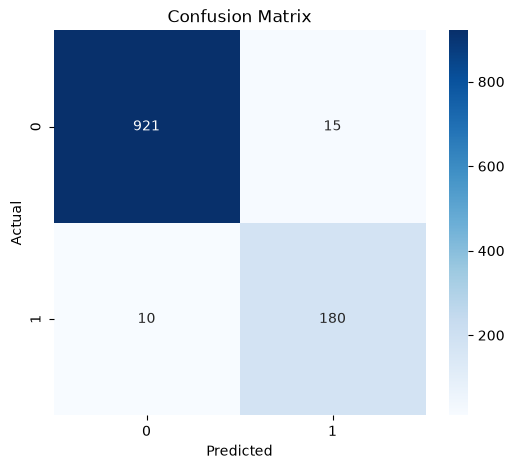

So khach churn thuc te bi bo sót (False Negative): 10
So khach churn duoc phat hien dung (True Positive): 180


In [7]:
cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'So khach churn thuc te bi bo sót (False Negative): {fn}')
print(f'So khach churn duoc phat hien dung (True Positive): {tp}')

## ROC Curve

Đo khả năng phân biệt hai lớp. AUC = 0.5 là ngẫu nhiên, AUC = 1 là hoàn hảo.

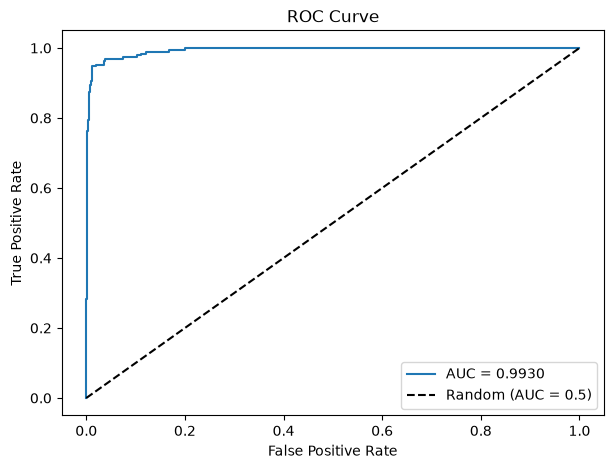

In [8]:
fpr, tpr, _ = roc_curve(y_test, probs)
roc_auc = roc_auc_score(y_test, probs)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.4f}')
plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

## Precision-Recall Curve

Phù hợp hơn ROC khi dữ liệu mất cân bằng (churn chỉ ~17%), vì PR-AUC tập trung vào lớp thiểu số.

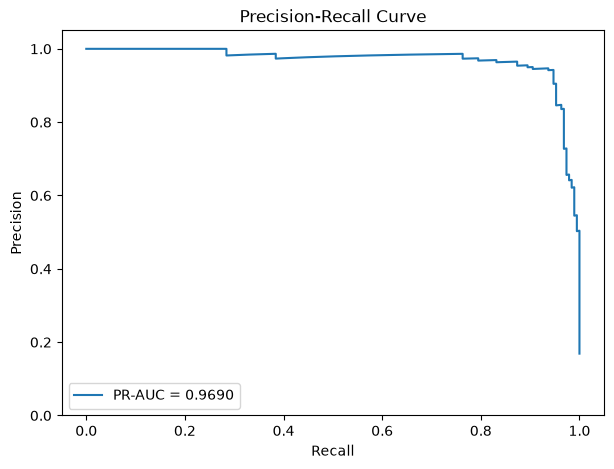

In [9]:
precision, recall, _ = precision_recall_curve(y_test, probs)
pr_auc = auc(recall, precision)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f'PR-AUC = {pr_auc:.4f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.ylim(0, 1.05)
plt.legend()
plt.show()

## Feature Importance

Giải thích model: biến nào ảnh hưởng nhất đến dự đoán churn. Tree model dùng `feature_importances_`, Logistic Regression dùng |coefficient|.

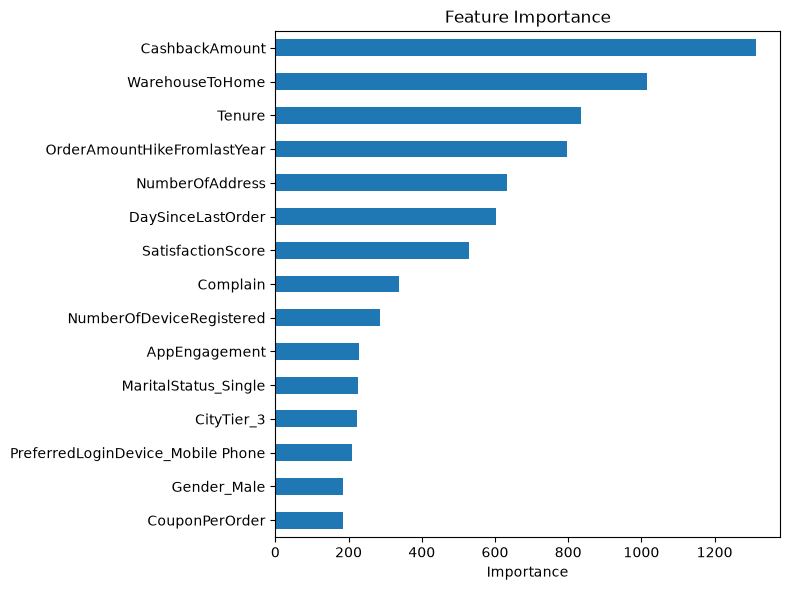

In [10]:
# Pipeline (LogisticRegression) lay buoc 'clf'; tree model dung truc tiep
est = model.named_steps['clf'] if hasattr(model, 'named_steps') else model

if hasattr(est, 'feature_importances_'):
    imp = pd.Series(est.feature_importances_, index=X_test.columns)
    title = 'Feature Importance'
else:
    imp = pd.Series(np.abs(est.coef_[0]), index=X_test.columns)
    title = '|Coefficient| (Logistic Regression)'

imp.nlargest(15).sort_values().plot(kind='barh', figsize=(8, 6))
plt.title(title)
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## Kết luận

- **Confusion matrix**: số False Negative cho thấy bao nhiêu khách churn bị bỏ sót — chỉ số quan trọng nhất về mặt nghiệp vụ.
- **ROC-AUC** đánh giá khả năng phân biệt tổng thể; **PR-AUC** đáng tin cậy hơn khi dữ liệu mất cân bằng.
- **Feature importance** giúp giải thích model và định hướng can thiệp (ví dụ: khách mới, khách khiếu nại, khách không mua gần đây).
- Nếu Recall chưa đạt yêu cầu: thử tuning hyperparameter, điều chỉnh ngưỡng phân loại (threshold), hoặc dùng SMOTE.